# Redes Neuronales en Machine Learning Supervisado
## Del Perceptrón simple al Perceptrón Multicapa (MLP)

**Proyecto:** RN — Machine Learning Supervisados
**Autor:** Nestor
**Repositorio base:** https://github.com/saguaraz/RN-Machine-Learning-Supervisados

Este notebook integra y pone en funcionamiento los dos ejemplos del proyecto, los amplía con las
compuertas **OR** y **XOR**, y cierra con una **comparación** entre el perceptrón simple y el MLP.

**Recorrido:**
1. Encuadre teórico (IA → Machine Learning → aprendizaje supervisado).
2. Perceptrón simple sobre compuertas lógicas linealmente separables: **AND** y **OR**.
3. El **problema XOR**: por qué una sola neurona no alcanza y cómo lo resuelve un MLP.
4. Clasificación multiclase real: **Iris** con `MLPClassifier`.
5. **Comparación** Perceptrón vs. MLP y conclusiones.

> Todas las salidas de este notebook son **deterministas y reproducibles** gracias a `random_state=42`.

---
## 1. Encuadre teórico

**Inteligencia Artificial (IA):** rama de la computación que construye sistemas capaces de reconocer
patrones y tomar decisiones a partir de datos.

**Machine Learning (ML):** subcampo de la IA donde el sistema *aprende* los parámetros de un modelo a
partir de ejemplos, en lugar de programarse regla por regla.

**Aprendizaje supervisado:** cada entrada $X$ viene acompañada de su respuesta correcta $y$ (la
*etiqueta*). Durante el entrenamiento el modelo compara su predicción con $y$ y ajusta sus parámetros
para reducir el error. Es exactamente el caso de todos los ejemplos de este notebook: construimos
pares $(X, y)$ conocidos y la red aprende a reproducirlos.

**Neurona artificial / Perceptrón:** unidad mínima de cómputo. Recibe entradas $X_i$, las pondera con
pesos $W_i$, suma un sesgo $b$ y aplica una función de activación:

$$ z = W_1 X_1 + W_2 X_2 + b \qquad \hat{y} = f(z)$$

Para el perceptrón clásico $f$ es un **escalón** (Heaviside): $f(z)=1$ si $z>0$, y $0$ en caso contrario.
La frontera de decisión es la recta $z=0$.

**Clave del proyecto — separabilidad lineal:** una sola neurona solo puede trazar **una recta**. Sirve
para problemas donde las clases se separan con una línea (AND, OR). Cuando no se puede (XOR), hacen
falta **varias neuronas en capas** (MLP).

---
## 2. Preparación del entorno

Importamos las librerías del ecosistema estándar de Python para ML: **NumPy** (cálculo matricial),
**scikit-learn** (modelos y métricas), **pandas** (tablas), **matplotlib** y **seaborn** (gráficos).

In [1]:
import warnings
warnings.filterwarnings("ignore")  # oculta el ConvergenceWarning para una salida limpia

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")
print("Entorno listo.")

Entorno listo.


---
## 3. El Perceptrón simple sobre compuertas lógicas

Una compuerta lógica recibe dos entradas binarias ($X_1, X_2 \in \{0,1\}$) y devuelve una salida
binaria. Su **tabla de verdad** completa (4 casos) es nuestro dataset supervisado: $X$ son los
operandos y $y$ la salida esperada.

Definimos una función reutilizable que entrena un perceptrón sobre cualquier compuerta, imprime la
tabla probada, la precisión, los parámetros aprendidos y grafica la **frontera de decisión**.

In [2]:
# Entradas comunes a todas las compuertas de 2 variables
X_gate = np.array([[0, 0],
                   [0, 1],
                   [1, 0],
                   [1, 1]])

def entrenar_compuerta(nombre, y):
    """Entrena un Perceptron sobre la compuerta y reporta su funcionamiento."""
    y = np.array(y)
    neurona = Perceptron(max_iter=100, random_state=42)
    neurona.fit(X_gate, y)
    pred = neurona.predict(X_gate)
    acc = accuracy_score(y, pred) * 100
    W, b = neurona.coef_[0], neurona.intercept_[0]

    print(f"===== COMPUERTA {nombre} =====")
    for entrada, obj, p in zip(X_gate, y, pred):
        estado = "OK" if obj == p else "ERROR"
        print(f"  {entrada} -> esperado: {obj} | predicho: {p}  [{estado}]")
    print(f"  Precisión: {acc:.1f}%   |   Iteraciones hasta converger: {neurona.n_iter_}")
    print(f"  Pesos aprendidos: W1={W[0]:.1f}, W2={W[1]:.1f}   Sesgo b={b:.1f}")
    return neurona, W, b, acc

def graficar_frontera(ax, nombre, y, W, b):
    """Dibuja los 4 puntos coloreados por clase y la recta de decisión z=0."""
    y = np.array(y)
    for (x1, x2), clase in zip(X_gate, y):
        color = "#2a9d8f" if clase == 1 else "#e76f51"
        marker = "o" if clase == 1 else "X"
        ax.scatter(x1, x2, c=color, s=320, marker=marker,
                   edgecolors="black", zorder=3)
    # Recta de decisión: W1*x1 + W2*x2 + b = 0  ->  x2 = -(W1*x1 + b)/W2
    xs = np.linspace(-0.4, 1.4, 100)
    if abs(W[1]) > 1e-9:
        ys = -(W[0] * xs + b) / W[1]
        ax.plot(xs, ys, "k--", lw=2, label="Frontera z=0")
        ax.legend(loc="upper right", fontsize=8)
    else:
        ax.text(0.5, 0.5, "Sin frontera\n(W=0)", ha="center", va="center",
                fontsize=11, color="firebrick", transform=ax.transAxes)
    ax.set_xlim(-0.4, 1.4); ax.set_ylim(-0.4, 1.4)
    ax.set_xlabel("X1"); ax.set_ylabel("X2")
    ax.set_title(f"Compuerta {nombre}")


### 3.1 Compuerta AND

Devuelve $1$ **solo** cuando ambas entradas son $1$. El único punto de clase $1$ está aislado en la
esquina $(1,1)$: una recta puede separarlo del resto, así que es **linealmente separable**.

In [3]:
neurona_and, W_and, b_and, _ = entrenar_compuerta("AND", [0, 0, 0, 1])

===== COMPUERTA AND =====
  [0 0] -> esperado: 0 | predicho: 0  [OK]
  [0 1] -> esperado: 0 | predicho: 0  [OK]
  [1 0] -> esperado: 0 | predicho: 0  [OK]
  [1 1] -> esperado: 1 | predicho: 1  [OK]
  Precisión: 100.0%   |   Iteraciones hasta converger: 9
  Pesos aprendidos: W1=2.0, W2=2.0   Sesgo b=-3.0


### 3.2 Compuerta OR

Devuelve $1$ cuando **al menos una** entrada es $1$. Ahora hay tres puntos de clase $1$ y uno solo de
clase $0$ en $(0,0)$; también se separa con una recta.

In [4]:
neurona_or, W_or, b_or, _ = entrenar_compuerta("OR", [0, 1, 1, 1])

===== COMPUERTA OR =====
  [0 0] -> esperado: 0 | predicho: 0  [OK]
  [0 1] -> esperado: 1 | predicho: 1  [OK]
  [1 0] -> esperado: 1 | predicho: 1  [OK]
  [1 1] -> esperado: 1 | predicho: 1  [OK]
  Precisión: 100.0%   |   Iteraciones hasta converger: 8
  Pesos aprendidos: W1=2.0, W2=2.0   Sesgo b=-1.0


### 3.3 Fronteras de decisión de AND y OR

Observá cómo el perceptrón trazó, en cada caso, **una recta** que deja los círculos (clase 1) de un
lado y las cruces (clase 0) del otro. Esa recta es el modelo lineal $z = W_1 X_1 + W_2 X_2 + b = 0$.

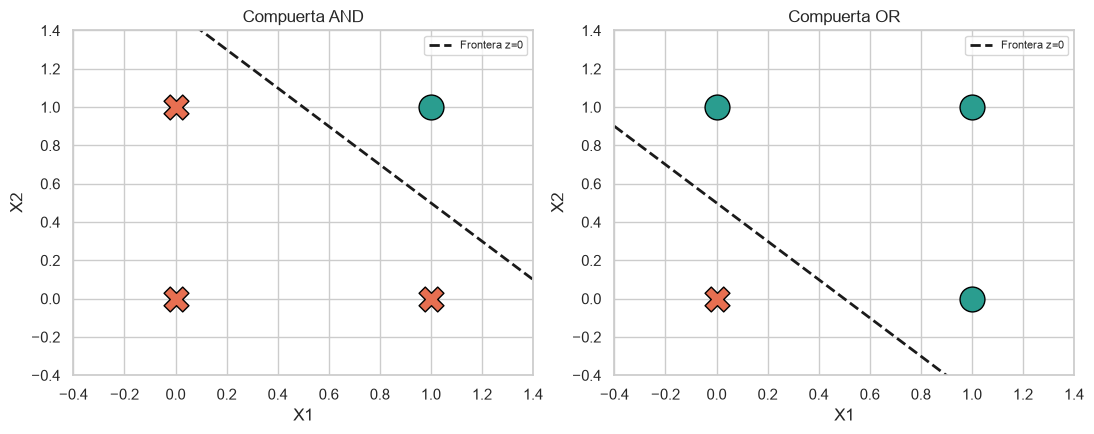

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
graficar_frontera(axes[0], "AND", [0, 0, 0, 1], W_and, b_and)
graficar_frontera(axes[1], "OR",  [0, 1, 1, 1], W_or,  b_or)
plt.tight_layout(); plt.show()

**Interpretación matemática (AND):** con $W_1=W_2=2.0$ y $b=-3.0$, la recta es
$2X_1 + 2X_2 - 3 = 0 \Rightarrow X_2 = -X_1 + 1.5$. Solo el punto $(1,1)$ da $z=1>0$ (clase 1); el resto
da $z<0$ (clase 0). Para OR, $b=-1.0$ corre la recta ($X_2 = -X_1 + 0.5$) de modo que tres puntos
quedan del lado positivo.

---
## 4. El problema XOR: el límite del perceptrón simple

La compuerta **XOR** (OR exclusivo) devuelve $1$ cuando las entradas son **distintas**:
$(0,1)$ y $(1,0)$ son clase $1$; $(0,0)$ y $(1,1)$ son clase $0$. Los puntos de cada clase quedan en
**esquinas opuestas**: **ninguna recta** puede separarlos. Es el ejemplo histórico de un problema
**no linealmente separable**.

Veamos qué ocurre al entrenar un perceptrón simple sobre XOR.

In [6]:
neurona_xor, W_xor, b_xor, acc_xor = entrenar_compuerta("XOR", [0, 1, 1, 0])

===== COMPUERTA XOR =====
  [0 0] -> esperado: 0 | predicho: 0  [OK]
  [0 1] -> esperado: 1 | predicho: 0  [ERROR]
  [1 0] -> esperado: 1 | predicho: 0  [ERROR]
  [1 1] -> esperado: 0 | predicho: 0  [OK]
  Precisión: 50.0%   |   Iteraciones hasta converger: 6
  Pesos aprendidos: W1=0.0, W2=0.0   Sesgo b=0.0


Como se ve, el perceptrón **no aprende**: la precisión se estanca en **50%** y los pesos quedan
en $W=[0,0]$ (no encontró ninguna recta útil). No es un error de código ni de hiperparámetros: es una
**limitación teórica** de un modelo lineal de una sola neurona.

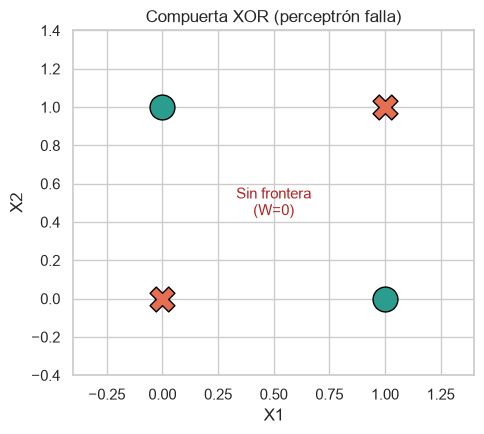

In [7]:
fig, ax = plt.subplots(figsize=(5, 4.5))
graficar_frontera(ax, "XOR (perceptrón falla)", [0, 1, 1, 0], W_xor, b_xor)
plt.tight_layout(); plt.show()

### 4.1 XOR resuelto con un Perceptrón Multicapa (MLP)

La solución es **apilar neuronas en capas**. Una **capa oculta** permite combinar varias rectas y
construir una frontera **no lineal**. Entrenamos un MLP con 1 capa oculta de 4 neuronas (activación
`tanh`), suficiente para resolver el XOR al 100%.

In [8]:
mlp_xor = MLPClassifier(hidden_layer_sizes=(4,), activation="tanh",
                        solver="adam", max_iter=5000, random_state=42)
mlp_xor.fit(X_gate, np.array([0, 1, 1, 0]))
pred_xor = mlp_xor.predict(X_gate)

print("===== XOR con MLP (2 -> 4 -> 1) =====")
for entrada, obj, p in zip(X_gate, [0, 1, 1, 0], pred_xor):
    print(f"  {entrada} -> esperado: {obj} | predicho: {p}")
print(f"  Precisión: {accuracy_score([0,1,1,0], pred_xor)*100:.1f}%   "
      f"Iteraciones: {mlp_xor.n_iter_}")

===== XOR con MLP (2 -> 4 -> 1) =====
  [0 0] -> esperado: 0 | predicho: 0
  [0 1] -> esperado: 1 | predicho: 1
  [1 0] -> esperado: 1 | predicho: 1
  [1 1] -> esperado: 0 | predicho: 0
  Precisión: 100.0%   Iteraciones: 2330


### 4.2 Frontera no lineal del MLP

Graficamos la región de decisión completa del MLP sobre el plano. A diferencia de la recta del
perceptrón, ahora la frontera es **curva** y logra aislar correctamente las dos esquinas de clase 1.

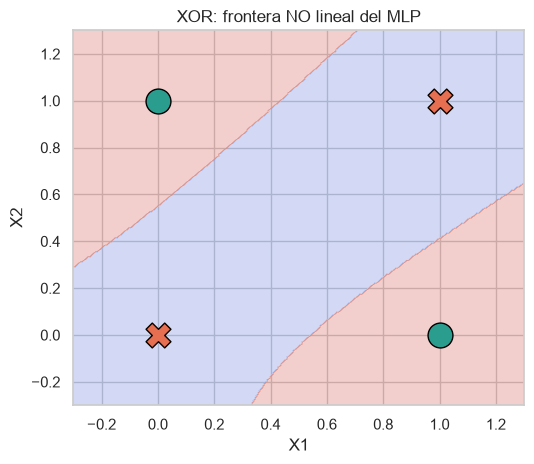

In [9]:
# Malla densa para pintar la región de decisión
xx, yy = np.meshgrid(np.linspace(-0.3, 1.3, 300), np.linspace(-0.3, 1.3, 300))
Z = mlp_xor.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(5.5, 4.8))
ax.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
for (x1, x2), clase in zip(X_gate, [0, 1, 1, 0]):
    color = "#2a9d8f" if clase == 1 else "#e76f51"
    marker = "o" if clase == 1 else "X"
    ax.scatter(x1, x2, c=color, s=320, marker=marker, edgecolors="black", zorder=3)
ax.set_title("XOR: frontera NO lineal del MLP")
ax.set_xlabel("X1"); ax.set_ylabel("X2")
plt.tight_layout(); plt.show()

---
## 5. Clasificación multiclase real: dataset Iris con MLP

Pasamos de la lógica binaria a un problema **real de 3 clases**. El dataset **Iris** (R. Fisher, 1936)
tiene 150 flores de 3 especies (*setosa*, *versicolor*, *virginica*), cada una descrita por 4 medidas:
largo y ancho de sépalo y de pétalo. Es el "Hola Mundo" de la clasificación.

Pipeline completo de ML supervisado: **cargar → explorar → dividir → escalar → entrenar → evaluar →
predecir → inspeccionar**.

### 5.1 Carga y exploración

In [10]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["target"] = iris.target
df["especie"] = df["target"].map({i: n for i, n in enumerate(iris.target_names)})
print("Primeras filas del dataset Iris:")
df.head()

Primeras filas del dataset Iris:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,especie
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


### 5.2 Preparación: división estratificada 80/20 y estandarización

Las redes neuronales son sensibles a la escala de las variables, por eso usamos `StandardScaler`
(media 0, desvío 1). `stratify=y` mantiene la misma proporción de clases en train y test. El escalador
se **ajusta solo con train** y luego se **aplica** a test (para no filtrar información del test).

In [11]:
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print(f"Entrenamiento: {X_train_s.shape[0]} muestras | Prueba: {X_test_s.shape[0]} muestras")

Entrenamiento: 120 muestras | Prueba: 30 muestras


### 5.3 Construcción y entrenamiento del MLP

Red con 1 capa oculta de **10 neuronas**, activación **ReLU**, optimizador **Adam** y hasta 500
iteraciones. Adam ajusta los pesos por **retropropagación** (backpropagation).

In [12]:
mlp = MLPClassifier(hidden_layer_sizes=(10,), activation="relu",
                    solver="adam", max_iter=500, random_state=42)
mlp.fit(X_train_s, y_train)
print(f"Modelo entrenado. Pérdida final: {mlp.loss_:.4f} en {mlp.n_iter_} iteraciones.")

Modelo entrenado. Pérdida final: 0.1787 en 500 iteraciones.


> **Nota sobre convergencia:** con 500 iteraciones scikit-learn emite un `ConvergenceWarning`
(lo silenciamos al inicio). No es un fallo: la pérdida igual baja a ~0.18 y la precisión es alta.
Se podría subir `max_iter` o usar `early_stopping` para eliminar el aviso.

### 5.4 Evaluación: reporte de clasificación

In [13]:
y_pred = mlp.predict(X_test_s)
print(classification_report(y_test, y_pred, target_names=iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



### 5.5 Visualización: curva de pérdida y matriz de confusión

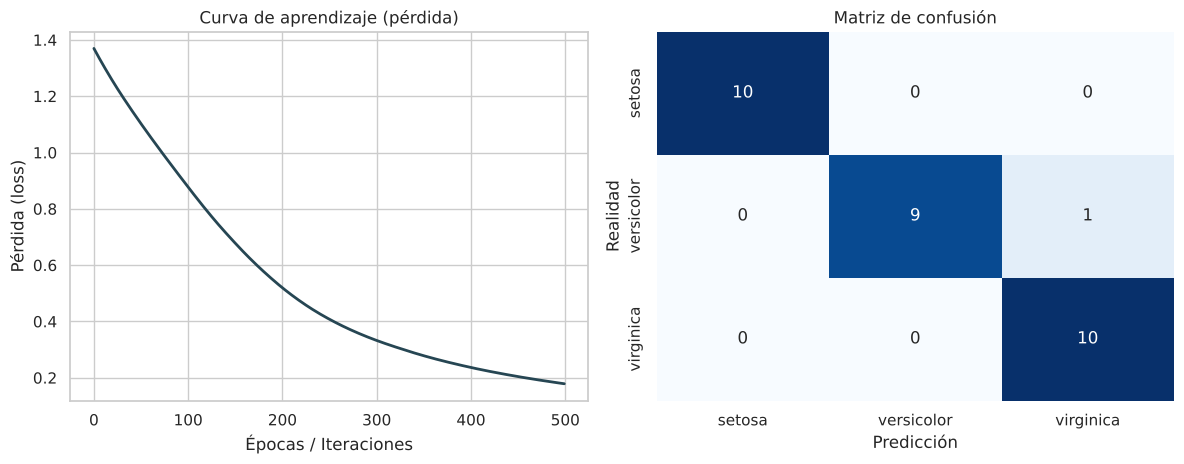

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

axes[0].plot(mlp.loss_curve_, color="#264653", lw=2)
axes[0].set_title("Curva de aprendizaje (pérdida)")
axes[0].set_xlabel("Épocas / Iteraciones"); axes[0].set_ylabel("Pérdida (loss)")

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=iris.target_names, yticklabels=iris.target_names, ax=axes[1])
axes[1].set_title("Matriz de confusión")
axes[1].set_xlabel("Predicción"); axes[1].set_ylabel("Realidad")
plt.tight_layout(); plt.show()

La curva de pérdida baja de forma sostenida (la red aprende). En la matriz de confusión, *setosa*
es perfecta; el único error es **1 flor *versicolor* clasificada como *virginica***, porque esas dos
especies se solapan en el tamaño de pétalo. De ahí el 97% de exactitud global (29/30).

### 5.6 Inferencia sobre una flor nueva

In [15]:
nueva_flor = np.array([[5.1, 3.5, 1.4, 0.2]])
nueva_flor_s = scaler.transform(nueva_flor)
pred = mlp.predict(nueva_flor_s)[0]
proba = mlp.predict_proba(nueva_flor_s)[0]

print(f"Medidas de la flor: {nueva_flor[0]}")
print(f"Especie predicha: {iris.target_names[pred]}")
for nombre, pr in zip(iris.target_names, proba):
    print(f"  P({nombre}) = {pr*100:.2f}%")

Medidas de la flor: [5.1 3.5 1.4 0.2]
Especie predicha: setosa
  P(setosa) = 98.73%
  P(versicolor) = 0.69%
  P(virginica) = 0.58%


### 5.7 Inspección de lo que aprendió la red (pesos y sesgos)

In [16]:
print("Pesos Entrada -> Capa Oculta  W(1):", mlp.coefs_[0].shape)      # (4, 10)
print("Sesgos Capa Oculta           b(1):", mlp.intercepts_[0].shape)  # (10,)
print("Pesos Capa Oculta -> Salida  W(2):", mlp.coefs_[1].shape)      # (10, 3)
print("Sesgos Salida                b(2):", mlp.intercepts_[1].shape)  # (3,)
print("\nParámetros entrenables totales:",
      sum(c.size for c in mlp.coefs_) + sum(i.size for i in mlp.intercepts_))

Pesos Entrada -> Capa Oculta  W(1): (4, 10)
Sesgos Capa Oculta           b(1): (10,)
Pesos Capa Oculta -> Salida  W(2): (10, 3)
Sesgos Salida                b(2): (3,)

Parámetros entrenables totales: 83


### 5.8 Diagrama de la arquitectura (4 → 10 → 3)

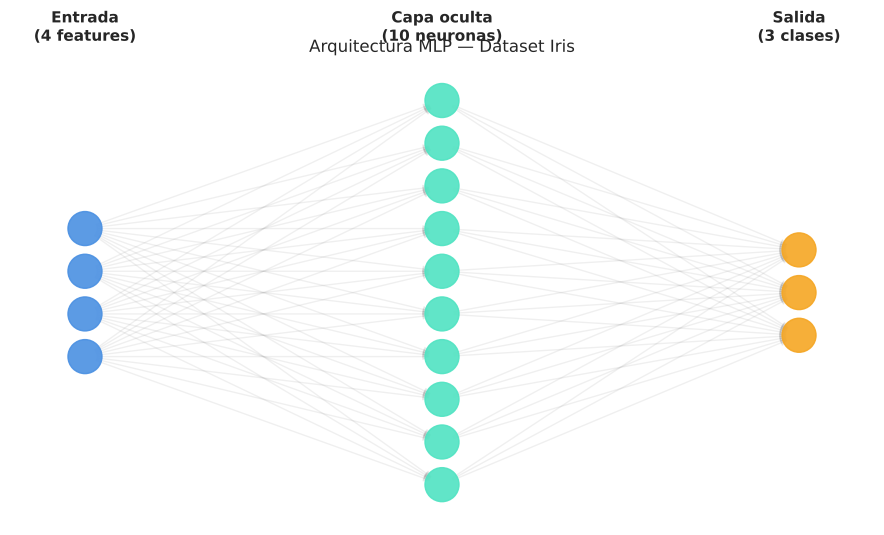

In [17]:
import networkx as nx

def dibujar_red(capas, nombres):
    G = nx.DiGraph(); pos = {}; colores = []
    paleta = ["#4A90E2", "#50E3C2", "#F5A623"]
    nid = 0
    for i, n in enumerate(capas):
        off = (max(capas) - n) / 2.0
        for j in range(n):
            pos[nid] = (i, j + off); G.add_node(nid); colores.append(paleta[i]); nid += 1
    base = 0
    for i in range(len(capas) - 1):
        act = range(base, base + capas[i])
        sig = range(base + capas[i], base + capas[i] + capas[i+1])
        for a in act:
            for s in sig:
                G.add_edge(a, s)
        base += capas[i]
    plt.figure(figsize=(9, 5.5))
    nx.draw_networkx_nodes(G, pos, node_color=colores, node_size=600, alpha=0.9)
    nx.draw_networkx_edges(G, pos, alpha=0.12, edge_color="gray")
    for i, nm in enumerate(nombres):
        plt.text(i, max(capas) + 0.4, nm, ha="center", fontsize=11, fontweight="bold")
    plt.title("Arquitectura MLP — Dataset Iris"); plt.axis("off"); plt.tight_layout(); plt.show()

dibujar_red([4, 10, 3],
            ["Entrada\n(4 features)", "Capa oculta\n(10 neuronas)", "Salida\n(3 clases)"])

---
## 6. Comparación: Perceptrón simple vs. MLP

| Aspecto | Perceptrón simple | Perceptrón Multicapa (MLP) |
|---|---|---|
| Clase scikit-learn | `Perceptron` | `MLPClassifier` |
| Estructura | 1 neurona | capas de entrada + oculta(s) + salida |
| Activación | escalón (Heaviside) | ReLU / tanh / sigmoide (no lineales) |
| Frontera de decisión | una **recta** (lineal) | superficies **no lineales** |
| Entrenamiento | regla del perceptrón | retropropagación + Adam |
| Resuelve AND / OR | ✅ sí (100%) | ✅ sí |
| Resuelve XOR | ❌ no (50%) | ✅ sí (100%) |
| Multiclase (Iris) | limitado | ✅ 97% |
| Probabilidades por clase | no | ✅ `predict_proba` |

**Síntesis.** El perceptrón simple es la **unidad fundamental** y basta para problemas **linealmente
separables** (AND, OR). Su límite —demostrado con el XOR— es que solo traza una recta. El MLP supera
ese límite **apilando neuronas en capas** con activaciones no lineales, lo que le permite aprender
fronteras curvas y resolver tanto el XOR como la clasificación multiclase de Iris. Este salto es,
históricamente, el origen de las redes neuronales profundas (*Deep Learning*).

---
## 7. Conclusiones

1. **Aprendizaje supervisado:** en todos los casos entrenamos con pares $(X, y)$ conocidos; la red
   ajustó sus pesos minimizando el error entre su predicción y la etiqueta real.
2. **Separabilidad lineal:** una sola neurona resuelve AND y OR con 100% de precisión y en muy pocas
   iteraciones (8–9), construyendo una recta de decisión exacta.
3. **El límite del perceptrón (XOR):** al no ser linealmente separable, una neurona se estanca en 50%.
   Esto **justifica** la necesidad de arquitecturas multicapa.
4. **El MLP generaliza:** con una capa oculta resuelve el XOR (frontera no lineal) y clasifica Iris al
   97%, entregando además probabilidades por clase.
5. **Reproducibilidad:** `random_state=42` garantiza que estos resultados se repitan en cada ejecución.

> **Para seguir:** probar más neuronas/capas en Iris, usar `early_stopping` para evitar el
> `ConvergenceWarning`, o graficar la matriz de dispersión (*pair plot*) del dataset para ver el
> solapamiento entre *versicolor* y *virginica*.